In [1]:
%pip install qiskit qiskit-aer matplotlib

Note: you may need to restart the kernel to use updated packages.


In [2]:
from qiskit import QuantumCircuit, transpile
from qiskit_aer import AerSimulator
from qiskit.visualization import plot_histogram
import matplotlib.pyplot as plt

# Create the quantum simulator
simulator = AerSimulator()

print("Qiskit libraries imported successfully!")

Qiskit libraries imported successfully!


ORIGINAL BELL-STATE CIRCUIT


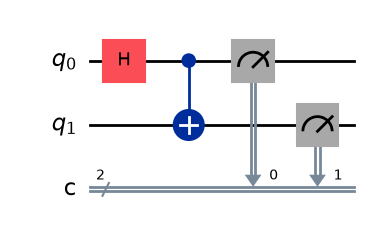

In [3]:
# Create a circuit with exactly 2 qubits and 2 classical bits
original = QuantumCircuit(2, 2)

# Step 1: Apply Hadamard gate
original.h(0)

# Step 2: Apply CNOT gate
original.cx(0, 1)

# Step 3: Measure both qubits
original.measure([0, 1], [0, 1])

# Display the original circuit
print("ORIGINAL BELL-STATE CIRCUIT")
display(original.draw("mpl"))

In [5]:
# Execute the original circuit for 100 shots
compiled_original = transpile(original, simulator)

job_original = simulator.run(
    compiled_original,
    shots=100
)

result_original = job_original.result()

# Extract measurement counts
counts_original = result_original.get_counts()

print("Original Circuit Measurement Results:")
print(counts_original)

print("\nTotal shots:", sum(counts_original.values()))

Original Circuit Measurement Results:
{'11': 53, '00': 47}

Total shots: 100


Counts: {'11': 53, '00': 47}


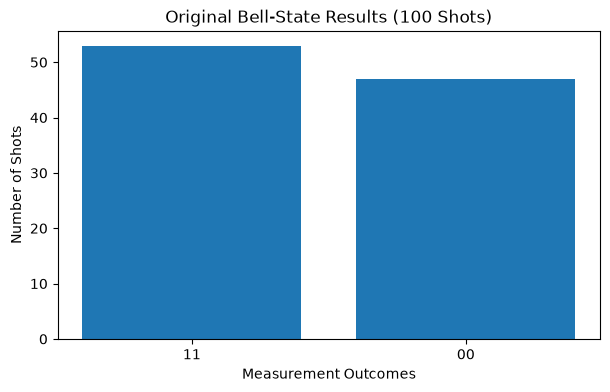

In [9]:
import matplotlib.pyplot as plt

print("Counts:", counts_original)

plt.figure(figsize=(7, 4))
plt.bar(
    list(counts_original.keys()),
    list(counts_original.values())
)
plt.xlabel("Measurement Outcomes")
plt.ylabel("Number of Shots")
plt.title("Original Bell-State Results (100 Shots)")
plt.show()

MODIFIED BELL-STATE CIRCUIT


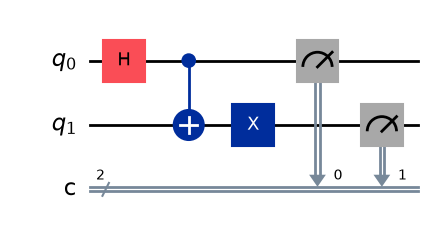

In [10]:
# Create a new circuit with exactly 2 qubits and 2 classical bits
modified = QuantumCircuit(2, 2)

# Original Bell-state gates
modified.h(0)
modified.cx(0, 1)

# Add one X gate to the second qubit
modified.x(1)

# Measure both qubits
modified.measure([0, 1], [0, 1])

# Display the modified circuit
print("MODIFIED BELL-STATE CIRCUIT")
display(modified.draw("mpl"))

In [11]:
# Execute the modified circuit for 100 shots
compiled_modified = transpile(modified, simulator)

job_modified = simulator.run(
    compiled_modified,
    shots=100
)

result_modified = job_modified.result()

# Extract measurement counts
counts_modified = result_modified.get_counts()

print("Modified Circuit Measurement Results:")
print(counts_modified)

print("\nTotal shots:", sum(counts_modified.values()))

Modified Circuit Measurement Results:
{'01': 55, '10': 45}

Total shots: 100


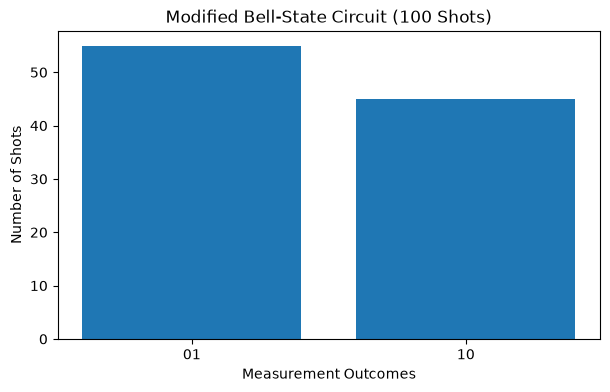

In [13]:


import matplotlib.pyplot as plt

plt.figure(figsize=(7, 4))

plt.bar(
counts_modified.keys(),
counts_modified.values()
)

plt.xlabel("Measurement Outcomes")
plt.ylabel("Number of Shots")
plt.title("Modified Bell-State Circuit (100 Shots)")

plt.show()




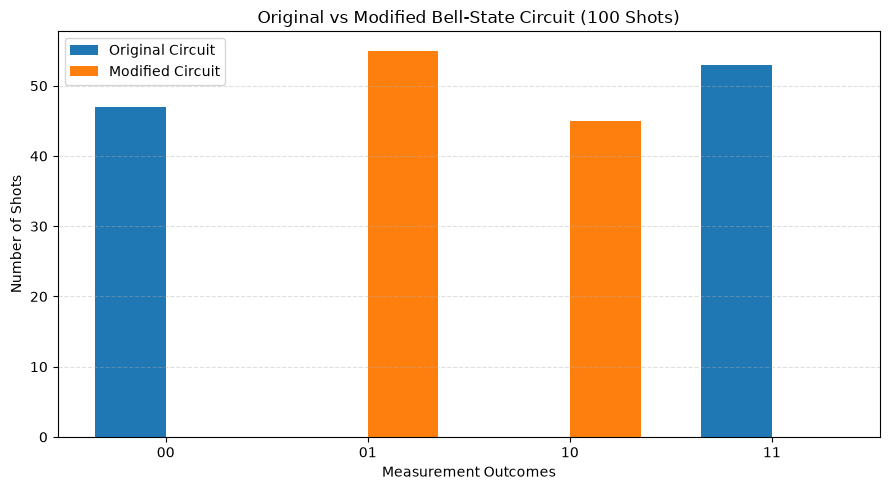

In [14]:


import matplotlib.pyplot as plt
import numpy as np

outcomes = ["00", "01", "10", "11"]

original_values = [counts_original.get(x, 0) for x in outcomes]
modified_values = [counts_modified.get(x, 0) for x in outcomes]

x = np.arange(len(outcomes))
width = 0.35

plt.figure(figsize=(9, 5))

plt.bar(
x - width/2,
original_values,
width,
label="Original Circuit"
)

plt.bar(
x + width/2,
modified_values,
width,
label="Modified Circuit"
)

plt.xlabel("Measurement Outcomes")
plt.ylabel("Number of Shots")
plt.title("Original vs Modified Bell-State Circuit (100 Shots)")
plt.xticks(x, outcomes)
plt.legend()
plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()




In [15]:
# Compare the counts of all four possible outcomes
outcomes = ["00", "01", "10", "11"]

print("MEASUREMENT COMPARISON")
print("-" * 45)
print(f"{'Outcome':<15}{'Original':<15}{'Modified':<15}")
print("-" * 45)

for outcome in outcomes:
    original_count = counts_original.get(outcome, 0)
    modified_count = counts_modified.get(outcome, 0)

    print(
        f"{outcome:<15}"
        f"{original_count:<15}"
        f"{modified_count:<15}"
    )

print("-" * 45)
print("Total original shots:", sum(counts_original.values()))
print("Total modified shots:", sum(counts_modified.values()))

MEASUREMENT COMPARISON
---------------------------------------------
Outcome        Original       Modified       
---------------------------------------------
00             47             0              
01             0              55             
10             0              45             
11             53             0              
---------------------------------------------
Total original shots: 100
Total modified shots: 100


In [16]:
# Verify the circuit constraints
assert original.num_qubits == 2
assert modified.num_qubits == 2

assert original.num_clbits == 2
assert modified.num_clbits == 2

assert sum(counts_original.values()) == 100
assert sum(counts_modified.values()) == 100

# Quantum gates before measurement:
# Original: H, CNOT = 2
# Modified: H, CNOT, X = 3
assert len(original.data) - 2 == 2
assert len(modified.data) - 2 == 3

print("All challenge requirements verified!")
print("Original circuit: 2 quantum gates")
print("Modified circuit: 3 quantum gates")
print("Qubits: 2 in each circuit")
print("Shots: 100 for each circuit")
print("Both qubits are measured in both circuits")

All challenge requirements verified!
Original circuit: 2 quantum gates
Modified circuit: 3 quantum gates
Qubits: 2 in each circuit
Shots: 100 for each circuit
Both qubits are measured in both circuits
